# Ejercicio 1 — Extracción de información de alojamientos AirBnB con LLMs

**Oporto · API de Groq**

El ejercicio tiene dos partes independientes:

1. **Extracción de entidades (LLM 1)** — de las descripciones más largas de los
   anuncios, un LLM devuelve un JSON con nombre, ubicación, características,
   tipo, tamaño, capacidad, comodidades y puntos de interés cercanos.
2. **Análisis de comentarios (LLM 2)** — un segundo LLM lee reseñas de huéspedes
   (en varios idiomas) y extrae sentimiento y valoración de limpieza, ubicación,
   relación calidad-precio, anfitrión y comodidad; después agregamos por alojamiento.

> **Datos.** Los CSV del curso no estaban disponibles, así que
> `data/listings1_cleaned.csv` y `data/Airbnb_reviews_5000.csv` se reconstruyen
> con los datos públicos de [Inside Airbnb](https://insideairbnb.com) (Oporto,
> snapshot 2026-09-19, licencia CC BY 4.0) mediante `scripts/preparar_datos.py`.
> Ese script limpia el HTML de las descripciones y elimina los datos personales
> (nombres de anfitriones y revisores).

### Decisiones de diseño (resumen)

| Decisión | Elección | Motivo |
| --- | --- | --- |
| Proveedor | **Groq** (API cloud) | Tier gratuito, rápido, salidas estructuradas; mismo cliente que el Ejercicio 2. |
| Modelo entidades | `openai/gpt-oss-120b` | Extracción abierta (listas, tamaños, lugares) → modelo grande. |
| Modelo comentarios | `openai/gpt-oss-20b` | Textos cortos y categorías cerradas → modelo pequeño basta. |
| Identificadores | `ref` corto (1, 2, 3…) | Los `id` de AirBnB tienen hasta 19 dígitos y un LLM puede alterarlos. |
| Formato salida | **JSON Schema estricto** | Groq garantiza tipos, campos obligatorios y valores `enum`; `temperature=0`. |
| Razonamiento | `reasoning_effort="low"` | Los gpt-oss razonan antes de responder; la tarea es sencilla y así se ahorran tokens. |
| Batching | 5 (entidades) / 10 (comentarios) | Menos llamadas sin truncar la respuesta por `max_tokens`. |
| Rate limits | Rotación de claves + `Retry-After` | Ante un 429 salta a otra clave; si todas al límite, espera lo justo. |

## 1. Configuración del entorno

Igual que en el Ejercicio 2: las claves Groq se leen del `.env` de la raíz del
repo (`GROQ_API_KEY` y, opcionalmente, `GROQ_API_KEY_2`, `GROQ_API_KEY_3`…). Un
`PoolClaves` rota entre ellas cuando una agota su cuota y todo el acceso al
modelo pasa por una única función `call_llm`.

In [1]:
import os
import re
import json
import time
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from groq import BadRequestError, Groq, RateLimitError

pd.set_option("display.max_colwidth", 120)


def cargar_claves():
    """Reúne GROQ_API_KEY y, si las hay, GROQ_API_KEY_2, GROQ_API_KEY_3, …"""
    claves = [os.getenv("GROQ_API_KEY")]
    i = 2
    while os.getenv(f"GROQ_API_KEY_{i}"):
        claves.append(os.getenv(f"GROQ_API_KEY_{i}"))
        i += 1
    claves = [c for c in claves if c]
    return list(dict.fromkeys(claves))  # sin duplicados, conservando el orden


class PoolClaves:
    """Varias claves Groq con rotación automática ante rate limit.

    Cuando una clave recibe un 429 queda en reposo hasta su hora de
    recuperación y saltamos a otra libre. Solo esperamos si TODAS están en
    reposo, y lo justo hasta que la primera se libere."""

    def __init__(self, claves):
        self.clientes = [Groq(api_key=c, max_retries=0) for c in claves]
        self.libre_en = [0.0] * len(self.clientes)
        self.i = 0

    @property
    def cliente(self):
        return self.clientes[self.i]

    def rotar_tras_429(self, segundos):
        """Deja la clave actual en reposo y salta a otra libre.
        Devuelve los segundos a esperar (0 si hay otra clave lista)."""
        self.libre_en[self.i] = time.time() + segundos
        ahora = time.time()
        n = len(self.clientes)
        for paso in range(1, n + 1):
            j = (self.i + paso) % n
            if self.libre_en[j] <= ahora:
                self.i = j
                return 0.0
        self.i = min(range(n), key=lambda j: self.libre_en[j])
        return max(0.0, self.libre_en[self.i] - ahora)


load_dotenv()  # busca el .env subiendo desde la carpeta del notebook hasta la raíz
CLAVES = cargar_claves()
assert CLAVES, "Falta GROQ_API_KEY. Copia .env.example a .env (raíz del repo) y pon tu(s) clave(s)."
pool = PoolClaves(CLAVES)

# Los Llama del Ejercicio 2 (llama-3.3-70b / llama-3.1-8b) ya no están en Groq.
MODELO_ENTIDADES = "openai/gpt-oss-120b"    # Parte 1: extracción abierta
MODELO_COMENTARIOS = "openai/gpt-oss-20b"   # Parte 2: clasificación de reseñas
plural = "s" if len(CLAVES) > 1 else ""
print(f"Cliente Groq listo ({len(CLAVES)} clave{plural} en el pool).")

Cliente Groq listo (1 clave en el pool).


### Parámetros

- `N_DESCRIPCIONES`: anuncios con la descripción más larga (el enunciado pide 10-20).
- `N_ALOJAMIENTOS_COMENTARIOS` × `MAX_COMENTARIOS_POR_ALOJAMIENTO`: reseñas que
  analiza la Parte 2 (5 × 10 = 50 como máximo).
- `MIN_CHARS_COMENTARIO`: los comentarios de una o dos palabras ("Great!",
  "Top") no aportan aspectos concretos; los quitamos con pandas, sin gastar
  llamadas al LLM.
- `TAM_BATCH_*` y `PAUSA_*`: filas por llamada y espera entre llamadas, por los
  mismos motivos que en el Ejercicio 2 (tokens por minuto del tier gratuito).

In [2]:
N_DESCRIPCIONES = 20

N_ALOJAMIENTOS_COMENTARIOS = 5
MAX_COMENTARIOS_POR_ALOJAMIENTO = 10
MIN_CHARS_COMENTARIO = 40

TAM_BATCH_ENTIDADES = 5      # descripciones de ~1.000 caracteres y respuesta larga
TAM_BATCH_COMENTARIOS = 10   # comentarios cortos y respuesta compacta

PAUSA_ENTIDADES = 6.0        # el 120B consume más tokens por llamada
PAUSA_COMENTARIOS = 2.0

DATA_DIR = Path("data")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

### Acceso al LLM y procesado por lotes

`call_llm` parte de la función del Ejercicio 2 (`temperature=0`, manejo del 429
con rotación de claves y `Retry-After`) con dos cambios:

- **`schema`**: en vez del *JSON mode* (que solo garantiza un JSON válido) usa
  **salidas estructuradas estrictas** (`json_schema` con `strict: true`). Groq
  obliga al modelo a respetar el esquema: campos obligatorios, tipos y valores
  `enum`. Así un `sentimiento` nunca puede salir como "positive" o "Muy positivo".
- **`reasoning_effort="low"`**: los modelos gpt-oss razonan antes de responder y
  esos tokens cuentan en `max_tokens` y en la cuota. Para extraer y clasificar
  basta un razonamiento corto.

`esquema_resultados` envuelve el esquema de un registro en
`{"resultados": [...]}`, porque la salida estructurada exige un objeto raíz.

Añadimos `procesar_por_lotes`, que reutilizan las dos partes:

1. trocea el DataFrame en lotes y llama al modelo una vez por lote,
2. **casa cada respuesta por su `ref`** (no por el orden),
3. **reintenta una a una** las filas que el modelo se haya saltado o las de un
   lote cuyo JSON no validó ni tras los reintentos de `call_llm`, y
4. avisa si alguna sigue sin respuesta, en vez de perderla en silencio.

In [3]:
def _espera_rate_limit(e, intento, base):
    """Segundos de reposo tras un 429: Retry-After, el tiempo del mensaje o backoff."""
    espera = None
    resp = getattr(e, "response", None)
    if resp is not None:
        cabecera = (resp.headers.get("retry-after")
                    or resp.headers.get("x-ratelimit-reset-tokens"))
        if cabecera:
            m = re.search(r"[\d.]+", str(cabecera))
            if m:
                espera = float(m.group())
    if espera is None:
        m = re.search(r"in ([\d.]+)s", str(e))
        if m:
            espera = float(m.group(1))
    if espera is None:
        espera = min(base * (2 ** (intento - 1)), 60.0)
    return espera + 1.0


def _fmt_espera(seg):
    seg = int(round(seg))
    return f"{seg} s" if seg < 60 else f"{seg // 60} min {seg % 60:02d} s"


def esquema_resultados(nombre, propiedades):
    """Esquema estricto {"resultados": [registro]} (todos los campos obligatorios)."""
    registro = {"type": "object", "additionalProperties": False,
                "required": list(propiedades), "properties": propiedades}
    return {"name": nombre, "strict": True, "schema": {
        "type": "object", "additionalProperties": False, "required": ["resultados"],
        "properties": {"resultados": {"type": "array", "items": registro}}}}


def call_llm(system, user, model, schema=None, max_tokens=1024, temperature=0.0,
             reasoning_effort="low", max_reintentos=8, pausa_base=2.0):
    """Llama a Groq (rotando de clave ante rate limit) y devuelve el texto.

    Con `schema` usa salida estructurada estricta; sin él, JSON mode."""
    kwargs = dict(
        model=model,
        temperature=temperature,
        max_tokens=max_tokens,
        reasoning_effort=reasoning_effort,
        messages=[
            {"role": "system", "content": system},
            {"role": "user", "content": user},
        ],
    )
    if schema:
        kwargs["response_format"] = {"type": "json_schema", "json_schema": schema}
    else:
        kwargs["response_format"] = {"type": "json_object"}

    fallos_json = 0
    for intento in range(1, max_reintentos + 1):
        try:
            resp = pool.cliente.chat.completions.create(**kwargs)
            return resp.choices[0].message.content
        except BadRequestError as e:
            # Con salida estructurada, Groq devuelve 400 "json_validate_failed" si el
            # modelo se desvía del esquema. Es esporádico: se reintenta un par de veces.
            # Cualquier otro 400 es un error de la petición y no tiene sentido repetirlo.
            if "json_validate_failed" not in str(e) or fallos_json == 2:
                raise
            fallos_json += 1
            print("  El modelo no respetó el esquema JSON, reintento.")
        except RateLimitError as e:
            if intento == max_reintentos:
                raise
            espera = pool.rotar_tras_429(_espera_rate_limit(e, intento, pausa_base))
            if espera:
                print(f"  Claves al límite, sigo en {_fmt_espera(espera)}.")
                time.sleep(espera)
            else:
                print("  Clave saturada, cambio a otra.")
        except Exception as e:  # noqa: BLE001 (errores transitorios de red/servidor)
            if intento == max_reintentos:
                raise
            espera = pausa_base * intento
            print(f"  Error de red ({type(e).__name__}), reintento en {_fmt_espera(espera)}.")
            time.sleep(espera)


def parse_json_seguro(texto):
    """Parsea JSON de forma defensiva: si viene con texto alrededor, recorta a las llaves."""
    try:
        return json.loads(texto)
    except json.JSONDecodeError:
        ini, fin = texto.find("{"), texto.rfind("}")
        if ini != -1 and fin != -1:
            return json.loads(texto[ini:fin + 1])
        raise


def _llamar_lote(lote, system, construir_prompt, modelo, schema, max_tokens, pausa):
    try:
        raw = call_llm(system, construir_prompt(lote), modelo, schema=schema,
                       max_tokens=max_tokens, pausa_base=pausa)
    except BadRequestError as e:
        if "json_validate_failed" not in str(e):
            raise
        print(f"  Lote sin JSON válido (refs {list(lote['ref'])}); se reintentarán una a una.")
        return {}
    resultados = parse_json_seguro(raw).get("resultados", [])
    validos = set(lote["ref"])
    salida = {}
    for r in resultados:
        try:
            ref = int(r.get("ref"))
        except (TypeError, ValueError):
            continue
        if ref in validos:
            salida[ref] = r
    return salida


def procesar_por_lotes(df, system, construir_prompt, modelo, schema, tam_batch, pausa, max_tokens):
    """Devuelve {ref: registro}. Reintenta individualmente las filas sin respuesta."""
    registros = {}
    n_lotes = (len(df) + tam_batch - 1) // tam_batch
    for i in range(0, len(df), tam_batch):
        lote = df.iloc[i:i + tam_batch]
        registros.update(_llamar_lote(lote, system, construir_prompt, modelo, schema,
                                      max_tokens, pausa))
        print(f"Lote {i // tam_batch + 1}/{n_lotes}: {len(lote)} filas enviadas")
        time.sleep(pausa)

    faltan = df[~df["ref"].isin(registros)]
    for _, fila in faltan.iterrows():
        print(f"  Reintento individual de ref {fila['ref']}")
        registros.update(_llamar_lote(faltan[faltan["ref"] == fila["ref"]], system,
                                      construir_prompt, modelo, schema, max_tokens, pausa))
        time.sleep(pausa)

    sin_respuesta = sorted(set(df["ref"]) - set(registros))
    print(f"Respuestas: {len(registros)}/{len(df)}"
          + (f" · sin respuesta: {sin_respuesta}" if sin_respuesta else ""))
    return registros


def validar_categorias(df, permitidos):
    """Cuenta valores fuera del vocabulario permitido en cada columna categórica."""
    for col, valores in permitidos.items():
        fuera = df.loc[~df[col].isin(valores), col]
        estado = "OK" if fuera.empty else f"{len(fuera)} fuera de rango: {fuera.unique().tolist()}"
        print(f"{col:<15} {estado}")

# Parte 1 — Extracción de entidades de las descripciones

## 2. Carga de los anuncios

`listings1_cleaned.csv` tiene un anuncio por fila. Para el LLM usamos solo
`name` (título) y `description`; el resto de columnas (`property_type`,
`accommodates`…) las guardamos para **contrastar** después lo que extrae el modelo.

In [4]:
listings = pd.read_csv(DATA_DIR / "listings1_cleaned.csv")
print("Dimensiones:", listings.shape)

longitud = listings["description"].str.len()
print("\nLongitud de description (caracteres):")
print(longitud.describe().round(1))
print(f"\nAnuncios con ≥ 950 caracteres: {(longitud >= 950).sum()}")

Dimensiones:

 (12742, 19)

Longitud de description (caracteres):
count    12742.0
mean       373.0
std        135.4
min          1.0
25%        297.0
50%        406.0
75%        466.0
max        990.0
Name: description, dtype: float64

Anuncios con ≥ 950 caracteres: 38


**Observación.** AirBnB corta la descripción en torno a los 1.000 caracteres, así
que hay muchos anuncios empatados cerca del máximo. Para que la selección sea
estable **desempatamos por `number_of_reviews`**: entre dos descripciones igual
de largas, preferimos el alojamiento con más actividad real.

## 3. Selección de las descripciones más largas

Cada anuncio recibe un **`ref` corto (1…N)**. Los `id` de AirBnB llegan a 19
dígitos (`1619507658268149552`) y un LLM puede cambiar un dígito al copiarlos, lo
que rompería el cruce de resultados. Con `ref` el modelo solo copia números de
uno o dos dígitos y el `id` real se recupera después con un `merge`.

In [5]:
def seleccionar_top_descripciones(df, n=20):
    """Devuelve los n anuncios con la descripción más larga (desempate: nº de reseñas)."""
    top = df.assign(longitud=df["description"].str.len())
    top = top.sort_values(["longitud", "number_of_reviews"], ascending=False).head(n)
    top = top.reset_index(drop=True)
    top.insert(0, "ref", range(1, len(top) + 1))
    return top


df_top = seleccionar_top_descripciones(listings, n=N_DESCRIPCIONES)
print(f"Anuncios seleccionados: {len(df_top)} "
      f"({df_top['longitud'].min()}-{df_top['longitud'].max()} caracteres)")
df_top[["ref", "id", "name", "longitud", "number_of_reviews"]]

Anuncios seleccionados: 20 (961-990 caracteres)


,ref,id,name,longitud,number_of_reviews
0,1,21957278,Explore Porto from a Radiant Apartment with a Balcony,990,87
1,2,1125233261044715120,Porto Garden Villas | Downtown 4 (w/jacuzzi),988,7
2,3,3912953,City Silhouette,985,245
3,4,3215881,Wonderful Apart Center Oporto!,982,196
4,5,681306,"Modern duplex apartment, 2 bathrooms and terrace",981,222
5,6,22878618,Light Filled Apartment with Terrace in the Heart of the City,978,524
6,7,736472,OPO.APT - Art Déco Apartment 110-1,977,250
7,8,735736,OPO.APT - Pateo Apartment 110-0,976,102
8,9,16954032,"Hang Poolside at a Fresh, Light-Filled Retreat in the Wilds",969,69
9,10,16647087,"Rustic, Romantic Flat in the Historic Center",967,726


## 4. Prompt de extracción de entidades (LLM 1)

### Diseño del prompt

- **Rol**: extractor de información de anuncios de alojamiento.
- **Definición de cada campo** con su tipo (texto, entero, lista) y un ejemplo
  de formato. Sin definiciones, `size` y `type` salen con formatos dispares.
- **`type` con vocabulario cerrado** para poder agregarlo después.
- **Regla anti-alucinación**: si un dato no aparece en el texto, `null` o `[]`.
  No queremos que el modelo "complete" la capacidad o el tamaño por intuición.
- **Idioma de salida fijo (español)**: las descripciones vienen en inglés,
  portugués, español… y queremos campos comparables entre anuncios.
- **Esquema estricto `ESQUEMA_ENTIDADES`**: el prompt explica *qué* significa
  cada campo y el esquema fija *la forma* (tipos, `null` permitido, `enum` de
  `type`). Por eso el prompt ya no repite la plantilla JSON.

### Modelo, lotes y tokens

- `openai/gpt-oss-120b`: hay que interpretar texto libre, deducir el barrio
  o distinguir una comodidad de un punto de interés. Un modelo pequeño confunde
  más estos campos.
- **5 anuncios por llamada** → 4 llamadas para 20 anuncios. Cada descripción ronda
  los 250-300 tokens y cada respuesta unos 250, así que un lote cabe holgado en
  `max_tokens=3000` sin truncar el JSON.
- No recortamos el texto: las descripciones ya vienen limitadas a ~1.000 caracteres.

In [6]:
TIPOS_ALOJAMIENTO = ["Apartamento", "Estudio", "Loft", "Casa", "Villa",
                     "Habitación privada", "Habitación compartida", "Suite de hotel", "Otro"]

SYSTEM_ENTIDADES = f"""Eres un extractor de información de anuncios de alojamientos turísticos de AirBnB en Oporto (Portugal).
Para cada anuncio recibes su título y su descripción. Extrae estos campos:

- name: nombre del alojamiento. Si la descripción da un nombre comercial (p. ej. "Oporto Ceuta Residences - Residence 10"), úsalo; si no, copia el título completo sin recortarlo.
- location: barrio, calle o zona de Oporto donde está, tal como se menciona. null si no se menciona.
- main_characteristics: lista de 3 a 5 rasgos que lo distinguen (estilo, vistas, reforma, terraza…).
- type: uno de {TIPOS_ALOJAMIENTO}.
- size: superficie si se menciona (p. ej. "55 m²"); si no, la distribución (p. ej. "2 dormitorios, 1 baño"); null si no hay nada.
- capacity: número máximo de huéspedes como entero. null si no se menciona.
- key_amenities: lista de comodidades del alojamiento (wifi, aire acondicionado, cocina equipada, lavadora…).
- proximity_highlights: lista de lugares o servicios cercanos (monumentos, metro, playa, río, restaurantes…).

Reglas:
- Usa SOLO información del texto. Si un dato no aparece, usa null (o [] en las listas). No lo deduzcas.
- Traduce al español todos los elementos de main_characteristics, key_amenities y proximity_highlights, aunque el anuncio esté en inglés o portugués (p. ej. "City view" → "Vistas a la ciudad"). Máx. 6 palabras por elemento.
- No traduzcas name ni los nombres propios de lugares (Ribeira, Rua de Santa Catarina, Torre dos Clérigos).
- Devuelve en "resultados" un objeto por cada anuncio, con el mismo "ref" que recibiste."""

TEXTO = {"type": "string"}
TEXTO_O_NULL = {"type": ["string", "null"]}
LISTA = {"type": "array", "items": TEXTO}

ESQUEMA_ENTIDADES = esquema_resultados("entidades_alojamiento", {
    "ref": {"type": "integer"},
    "name": TEXTO,
    "location": TEXTO_O_NULL,
    "main_characteristics": LISTA,
    "type": {"type": "string", "enum": TIPOS_ALOJAMIENTO},
    "size": TEXTO_O_NULL,
    "capacity": {"type": ["integer", "null"]},
    "key_amenities": LISTA,
    "proximity_highlights": LISTA,
})


def construir_prompt_entidades(lote):
    bloques = [
        f'ref {fila["ref"]}\nTítulo: {fila["name"]}\nDescripción: """{fila["description"]}"""'
        for _, fila in lote.iterrows()
    ]
    return (f"Extrae los campos de estos {len(lote)} anuncios (un objeto por anuncio):\n\n"
            + "\n\n---\n\n".join(bloques))


print(construir_prompt_entidades(df_top.head(1))[:700], "…")

Extrae los campos de estos 1 anuncios (un objeto por anuncio):

ref 1
Título: Explore Porto from a Radiant Apartment with a Balcony
Descripción: """Opening November 2017, Oporto Ceuta Residences - Residence 10 is located on the 5th floor accessible by 2 elevators in a prestigious and revamped 50's style building with 7 floors. The apartment is comprised with 1 bedroom allowing up to 4 people and 1 baby cot, if needed. Our signature bed, equipped with premium bed linen and topper, offers you a nice night's sleep where our electric blinds will keep daylight totally away, with premium isolation sound. The apartment is comprised with 1 bathroom fully equipped.
Featuring city view, the living roo …


In [7]:
entidades = procesar_por_lotes(
    df_top, SYSTEM_ENTIDADES, construir_prompt_entidades, MODELO_ENTIDADES, ESQUEMA_ENTIDADES,
    tam_batch=TAM_BATCH_ENTIDADES, pausa=PAUSA_ENTIDADES, max_tokens=3000,
)

Lote 1/4: 5 filas enviadas


Lote 2/4: 5 filas enviadas


Lote 3/4: 5 filas enviadas


Lote 4/4: 5 filas enviadas


Respuestas: 20/20


### DataFrame de entidades

Unimos la salida del LLM con el `id` real del anuncio a través de `ref` y
mostramos el JSON de un anuncio tal como lo devuelve el modelo.

In [8]:
COLUMNAS_ENTIDADES = ["name", "location", "main_characteristics", "type", "size",
                      "capacity", "key_amenities", "proximity_highlights"]

df_entidades = (pd.DataFrame(list(entidades.values()))
                .reindex(columns=["ref"] + COLUMNAS_ENTIDADES)
                .astype({"ref": int}))
df_entidades["capacity"] = pd.to_numeric(df_entidades["capacity"], errors="coerce").astype("Int64")
df_entidades = (df_top[["ref", "id"]]
                .merge(df_entidades, on="ref", how="left")
                .sort_values("ref"))

print(json.dumps(entidades[1], ensure_ascii=False, indent=2))
df_entidades

{
  "ref": 1,
  "name": "Oporto Ceuta Residences - Residence 10",
  "location": null,
  "main_characteristics": [
    "Estilo años 50",
    "Vistas a la ciudad",
    "Cortinas eléctricas",
    "Aislamiento acústico"
  ],
  "type": "Apartamento",
  "size": "1 dormitorio, 1 baño",
  "capacity": 4,
  "key_amenities": [
    "wifi",
    "aire acondicionado",
    "cocina equipada",
    "tv inteligente",
    "cama premium"
  ],
  "proximity_highlights": []
}


,ref,id,name,location,main_characteristics,type,size,capacity,key_amenities,proximity_highlights
0,1,21957278,Oporto Ceuta Residences - Residence 10,NaN,"[Estilo años 50, Vistas a la ciudad, Cortinas eléctricas, Aislamiento acústico]",Apartamento,"1 dormitorio, 1 baño",4,"[wifi, aire acondicionado, cocina equipada, tv inteligente, cama premium]",[]
1,2,1125233261044715120,Porto Garden Villas | Downtown 4 (w/jacuzzi),NaN,"[Jardín común, Jacuzzi compartido, Vista panorámica]",Villa,NaN,4,"[wifi de alta velocidad, tv led, cocina totalmente equipada, secador de pelo]",[tiendas y supermercados]
2,3,3912953,City Silhouette,centro histórico de Oporto,"[Vistas a la silueta de la ciudad, Ubicación céntrica, Cercano a monumentos]",Apartamento,NaN,<NA>,[],"[Teatro de São João, Torre dos Clérigos, Mosteiro de São Bento da Vitória, Puente D. Luis, Ribeira (río Douro), Metr..."
3,4,3215881,Wonderful Apart Center Oporto!,centro histórico de Porto,"[Wifi, Calefacción, Cocina equipada, Capacidad 7 personas]",Apartamento,NaN,7,"[wifi, calefacción, cocina equipada]","[Ribeira do Porto, Cavas de Vino de Oporto, Metro (200 m), Puentes del Douro]"
4,5,681306,"Modern duplex apartment, 2 bathrooms and terrace",barrio Olival (antiguo barrio judío),"[Patio trasero, Terraza, Edificio del siglo XIX, Renovado con comodidades modernas]",Apartamento,2 baños,<NA>,[],"[Restaurante Caraças, Cafés y tiendas renovadas, Río Douro, Playas y esplanadas]"
5,6,22878618,Light Filled Apartment with Terrace in the Heart of the City,Picaria,"[Luminoso, Terraza, Centro de la ciudad]",Apartamento,"1 dormitorio, 1 sofá cama",4,"[Cocina equipada, Toallas, Ropa de cama, Artículos de aseo]","[Atracciones principales a pie, Corazón de la ciudad]"
6,7,736472,OPO.APT - Art Déco Apartment 110-1,Cedofeita,"[Art Deco, Edificio restaurado, Dos dormitorios]",Apartamento,"2 dormitorios, 1 baño",6,"[Internet cable, Wi‑Fi, Aire acondicionado, Calefacción, Ropa de cama, Toallas]","[Cerca del centro, Entre Baixa y Boavista]"
7,8,735736,OPO.APT - Pateo Apartment 110-0,Cedofeita,"[Jardín privado, Edificio Art Deco, Terraza al aire libre]",Apartamento,"2 dormitorios, 1 baño",6,"[Internet cable, Wi‑Fi, Aire acondicionado, Calefacción, Ropa de cama, Muebles de exterior]","[Cerca del centro, Entre Baixa y Boavista]"
8,9,16954032,Quinta da Agraceira,NaN,"[Propiedad del siglo XVIII, Vista al río Douro, Gran jardín, Piscina]",Casa,NaN,<NA>,"[Piscina, Capilla, Jardín]","[Río Douro, Región del Alto Douro, A 10 km de Porto]"
9,10,16647087,"Rustic, Romantic Flat in the Historic Center",centro histórico,"[Estilo vintage, Paredes de piedra, Pisos con patrón]",Apartamento,"1 dormitorio, 1 sofá cama",4,"[Cocina equipada, Ventilador eléctrico, Calefacción, Ropa de cama, Toallas]","[Patrimonio de la Humanidad, Centro histórico]"


### Comprobación de coherencia

Las columnas estructuradas del dataset original permiten verificar al LLM sin
etiquetar nada a mano:

- **`capacity` vs `accommodates`** — capacidad extraída del texto frente a la
  declarada por el anfitrión.
- **`type` vs `property_type`** — tipo normalizado frente al de AirBnB.
- **Campos vacíos** — cuántas veces el modelo dejó un campo en `null`/`[]`
  (información que la descripción no da).

In [9]:
validar_categorias(df_entidades, {"type": TIPOS_ALOJAMIENTO})

check = df_entidades.merge(df_top[["ref", "accommodates", "property_type"]], on="ref")
con_capacidad = check.dropna(subset=["capacity"])
coincide = (con_capacidad["capacity"] == con_capacidad["accommodates"]).mean()
print(f"\nCapacidad mencionada en {len(con_capacidad)}/{len(check)} descripciones; "
      f"coincide con 'accommodates' en el {coincide:.0%}.")

vacios = {c: int(df_entidades[c].apply(lambda v: v is None or v is pd.NA
                                       or (isinstance(v, float) and pd.isna(v))
                                       or (isinstance(v, list) and not v)).sum())
          for c in COLUMNAS_ENTIDADES}
print("Campos vacíos por columna:", vacios)

check[["ref", "type", "property_type", "capacity", "accommodates"]]

type            OK

Capacidad mencionada en 9/20 descripciones; coincide con 'accommodates' en el 78%.
Campos vacíos por columna: {'name': 0, 'location': 3, 'main_characteristics': 0, 'type': 0, 'size': 12, 'capacity': 11, 'key_amenities': 4, 'proximity_highlights': 3}


,ref,type,property_type,capacity,accommodates
0,1,Apartamento,Entire serviced apartment,4,4
1,2,Villa,Entire home,4,4
2,3,Apartamento,Entire rental unit,<NA>,6
3,4,Apartamento,Entire rental unit,7,6
4,5,Apartamento,Entire rental unit,<NA>,4
5,6,Apartamento,Entire rental unit,4,4
6,7,Apartamento,Entire rental unit,6,6
7,8,Apartamento,Entire rental unit,6,6
8,9,Casa,Entire home,<NA>,6
9,10,Apartamento,Entire rental unit,4,4


**Observaciones** (ejecución guardada)

- **`capacity`** solo aparece en menos de la mitad de las descripciones, y donde
  aparece coincide casi siempre con `accommodates`. Las diferencias vienen del
  propio texto (la descripción dice 7 y el anfitrión declara 6), no de que el
  modelo se invente el dato: la regla "si no aparece, `null`" funciona.
- **`size`** queda vacío en más de la mitad: los anuncios rara vez dan los m².
- **`type`** es coherente con `property_type`. El caso dudoso es la habitación de
  un *bed and breakfast*, que el modelo clasifica como `Casa` porque la
  descripción habla de la casa completa: límite de un vocabulario cerrado.
- **`key_amenities`** sale vacío cuando la descripción se centra en la ubicación.
  En un caso real convendría combinarlo con la columna `amenities` del dataset,
  que es estructurada.

In [10]:
def lista_a_texto(v):
    return "; ".join(v) if isinstance(v, list) else v


df_entidades.apply(lambda col: col.map(lista_a_texto)).to_csv(
    OUT_DIR / "entidades_alojamientos.csv", index=False, encoding="utf-8-sig")
(OUT_DIR / "entidades_alojamientos.json").write_text(
    json.dumps([entidades[r] for r in sorted(entidades)], ensure_ascii=False, indent=2),
    encoding="utf-8")
print("Guardado en:", (OUT_DIR / "entidades_alojamientos.csv").resolve())

Guardado en: C:\dev\pontia\Prompt engineer\Ejercicio-Prompt-Engineer\ejercicio-1\output\entidades_alojamientos.csv


# Parte 2 — Análisis de comentarios

## 5. Carga de las reseñas

`Airbnb_reviews_5000.csv` contiene las 5.000 reseñas más recientes del snapshot
(septiembre de 2026), con `listing_id`, `review_id`, `date` y `comments`.

In [11]:
reviews = pd.read_csv(DATA_DIR / "Airbnb_reviews_5000.csv")
print("Dimensiones:", reviews.shape)
print(f"Alojamientos distintos: {reviews['listing_id'].nunique()}")
print("\nLongitud de comments (caracteres):")
print(reviews["comments"].str.len().describe().round(1))
reviews.head(3)

Dimensiones: (5000, 4)
Alojamientos distintos: 3235

Longitud de comments (caracteres):
count    5000.0
mean      228.0
std       202.9
min         1.0
25%        81.0
50%       169.0
75%       312.0
max      1000.0
Name: comments, dtype: float64


,listing_id,review_id,date,comments
0,1686106986228936539,1778910297269202597,2026-09-20,"포르투 여행 동안 머문 숙소 중 정말 정말 만족스러웠습니다.\n위치가 너무 좋아서 상벤투역, 볼량시장, 렐루서점 등 주요 관광지를 대부분 걸어서 다닐 수 있었고, 주변에 식당과 카페도 많아서 여행하는 내내 정..."
1,602719622627107434,1778900489384556287,2026-09-20,"Appartamento carino, bagno molto piccolo posizione eccellente. L’appartamento richiede maggiore manutenzione ed una ..."
2,20727957,1778874998909751522,2026-09-20,Sandra and Pedro are the consummate hosts! Their beautiful apartment is in the perfect location—within easy walking ...


## 6. Selección de comentarios

Analizar las 5.000 reseñas no aporta más al ejercicio y consumiría la cuota
diaria del tier gratuito. Elegimos una muestra que permita **comparar
alojamientos**:

1. quitamos los comentarios de menos de `MIN_CHARS_COMENTARIO` caracteres
   ("Great!", "Top") — filtro determinista con pandas, no necesita un LLM;
2. tomamos los `N_ALOJAMIENTOS_COMENTARIOS` alojamientos con más comentarios útiles;
3. de cada uno, sus `MAX_COMENTARIOS_POR_ALOJAMIENTO` comentarios más largos.

Igual que en la Parte 1, cada comentario recibe un `ref` corto.

In [12]:
utiles = reviews[reviews["comments"].str.len() >= MIN_CHARS_COMENTARIO].copy()
print(f"Comentarios con ≥ {MIN_CHARS_COMENTARIO} caracteres: {len(utiles)}/{len(reviews)}")

top_alojamientos = utiles["listing_id"].value_counts().head(N_ALOJAMIENTOS_COMENTARIOS).index
df_coment = (utiles[utiles["listing_id"].isin(top_alojamientos)]
             .assign(longitud=lambda d: d["comments"].str.len())
             .sort_values(["listing_id", "longitud"], ascending=[True, False])
             .groupby("listing_id").head(MAX_COMENTARIOS_POR_ALOJAMIENTO)
             .reset_index(drop=True))
df_coment.insert(0, "ref", range(1, len(df_coment) + 1))

print(f"Comentarios a analizar: {len(df_coment)} de {len(top_alojamientos)} alojamientos")
df_coment.groupby("listing_id").size().rename("comentarios").to_frame()

Comentarios con ≥ 40 caracteres: 4444/5000
Comentarios a analizar: 31 de 5 alojamientos


,comentarios
listing_id,
14923525,7
1431701275987721888,8
1550809152970811724,5
1570381141109000835,5
1710402650992018559,6


## 7. Prompt de análisis de comentarios (LLM 2)

### Formato de salida (elegido)

Por cada comentario:

| Campo | Valores |
| --- | --- |
| `idioma` | código ISO 639-1 (`en`, `es`, `pt`, `fr`…) |
| `sentimiento` | Positivo · Negativo · Neutral · Mixto |
| `limpieza`, `ubicacion`, `calidad_precio`, `anfitrion`, `comodidad` | Positivo · Negativo · Neutral · No mencionado |
| `puntos_fuertes`, `quejas` | listas de textos breves en español |
| `resumen` | una frase en español |

### Decisiones

- **Aspectos con "No mencionado"** separado de "Neutral": la mayoría de
  comentarios hablan de 2-3 aspectos, y confundir "no lo menciona" con "opinión
  neutra" distorsionaría los porcentajes por alojamiento.
- **"Mixto" en sentimiento** para comentarios con elogios y quejas a la vez,
  frecuentes en las reseñas largas.
- **Definición de cada aspecto** en el prompt (p. ej. `comodidad` = cama,
  equipamiento, temperatura, ruido) para que el modelo no los mezcle.
- **Salida siempre en español**, sea cual sea el idioma de la reseña, para poder
  agregar los textos. En una primera versión el 20B copiaba las quejas en chino o
  alemán; se corrigió con ejemplos de traducción en el prompt de sistema y un
  recordatorio al final del mensaje de usuario (lo último que lee el modelo).

### Modelo, lotes y tokens

- `openai/gpt-oss-20b`: comentarios cortos (~230 caracteres de media) y casi
  todo categorías cerradas; el modelo pequeño es suficiente, más rápido y tiene
  su propia cuota, así que no compite con el 120B de la Parte 1.
- Los valores permitidos van **en el prompt** (para que el modelo entienda cuándo
  usar cada uno) **y en el esquema** como `enum` (para que no pueda salirse).
- **10 comentarios por llamada** → ~5 llamadas. La respuesta por comentario
  ronda los 120 tokens; `max_tokens=3000` deja margen sin truncar.

In [13]:
VALORES_ASPECTO = ["Positivo", "Negativo", "Neutral", "No mencionado"]
VALORES_SENTIMIENTO = ["Positivo", "Negativo", "Neutral", "Mixto"]
ASPECTOS = ["limpieza", "ubicacion", "calidad_precio", "anfitrion", "comodidad"]

SYSTEM_COMENTARIOS = f"""Eres un analista de reseñas de huéspedes de AirBnB. Las reseñas pueden estar en cualquier idioma.
Para cada reseña extrae:

- idioma: código ISO 639-1 del idioma de la reseña (en, es, pt, fr, de…).
- sentimiento: {VALORES_SENTIMIENTO}. "Mixto" si combina elogios y quejas claras.
- Valoración de cada aspecto, con uno de {VALORES_ASPECTO}:
  - limpieza: limpieza del alojamiento, ropa de cama, baño.
  - ubicacion: situación, cercanía a sitios de interés, transporte, barrio.
  - calidad_precio: relación entre lo pagado y lo recibido.
  - anfitrion: comunicación, atención, check-in, ayuda del anfitrión.
  - comodidad: cama, equipamiento, temperatura, ruido, espacio.
  Usa "No mencionado" si la reseña no habla de ese aspecto. "Neutral" solo si lo menciona sin valorarlo.
- puntos_fuertes: lista de lo que elogia (máx. 5 palabras por elemento). [] si nada.
- quejas: lista de lo que critica (máx. 5 palabras por elemento). [] si nada.
- resumen: una frase de máximo 20 palabras.

IDIOMA DE SALIDA: puntos_fuertes, quejas y resumen van SIEMPRE en español. Si la reseña está en otro idioma, tradúcelos (p. ej. "Bett sehr bequem" → "Cama muy cómoda", "房间很干净" → "Habitación muy limpia"). Nunca copies frases en el idioma original.
Devuelve en "resultados" un objeto por reseña, con el mismo "ref"."""

ESQUEMA_COMENTARIOS = esquema_resultados("analisis_comentario", {
    "ref": {"type": "integer"},
    "idioma": {"type": "string"},
    "sentimiento": {"type": "string", "enum": VALORES_SENTIMIENTO},
    **{a: {"type": "string", "enum": VALORES_ASPECTO} for a in ASPECTOS},
    "puntos_fuertes": {"type": "array", "items": {"type": "string"}},
    "quejas": {"type": "array", "items": {"type": "string"}},
    "resumen": {"type": "string"},
})


def construir_prompt_comentarios(lote):
    lineas = [f'ref {fila["ref"]}: """{fila["comments"]}"""' for _, fila in lote.iterrows()]
    # El recordatorio del idioma va también al final: es lo último que lee el modelo
    # antes de responder y el 20B tiende a copiar el idioma de la reseña.
    return (f"Analiza estas {len(lote)} reseñas (un objeto por reseña):\n\n"
            + "\n\n".join(lineas)
            + "\n\nRecuerda: puntos_fuertes, quejas y resumen, traducidos al español.")

In [14]:
analisis = procesar_por_lotes(
    df_coment, SYSTEM_COMENTARIOS, construir_prompt_comentarios, MODELO_COMENTARIOS,
    ESQUEMA_COMENTARIOS, tam_batch=TAM_BATCH_COMENTARIOS, pausa=PAUSA_COMENTARIOS, max_tokens=3000,
)

Lote 1/4: 10 filas enviadas


Lote 2/4: 10 filas enviadas


Lote 3/4: 10 filas enviadas


  Claves al límite, sigo en 2 s.


Lote 4/4: 1 filas enviadas


Respuestas: 31/31


In [15]:
COLUMNAS_COMENT = ["idioma", "sentimiento"] + ASPECTOS + ["puntos_fuertes", "quejas", "resumen"]

df_analisis = (pd.DataFrame(list(analisis.values()))
               .reindex(columns=["ref"] + COLUMNAS_COMENT)
               .astype({"ref": int}))
df_analisis = (df_coment[["ref", "listing_id", "review_id", "date", "comments"]]
               .merge(df_analisis, on="ref", how="left")
               .sort_values("ref"))

validar_categorias(df_analisis, {"sentimiento": VALORES_SENTIMIENTO,
                                 **{a: VALORES_ASPECTO for a in ASPECTOS}})
df_analisis[["ref", "listing_id", "idioma", "sentimiento"] + ASPECTOS + ["resumen"]].head(10)

sentimiento     OK
limpieza        OK
ubicacion       OK
calidad_precio  OK
anfitrion       OK
comodidad       OK


,ref,listing_id,idioma,sentimiento,limpieza,ubicacion,calidad_precio,anfitrion,comodidad,resumen
0,1,14923525,fr,Positivo,Positivo,Positivo,No mencionado,Positivo,Positivo,"Excelente apartamento, limpio, ubicación ideal y servicio impecable."
1,2,14923525,de,Positivo,Positivo,Positivo,No mencionado,Positivo,Positivo,"Limpieza perfecta, anfitrión atento y ubicación conveniente al aeropuerto."
2,3,14923525,pt,Positivo,Positivo,Positivo,No mencionado,Positivo,Positivo,"Espacio acogedor, muy limpio y anfitrión muy amable."
3,4,14923525,en,Positivo,Positivo,Positivo,No mencionado,Positivo,Positivo,"Ubicación excelente, jardín bonito y grandes ventanales."
4,5,14923525,pt,Positivo,Positivo,Positivo,No mencionado,Positivo,Positivo,"Espacio bien equipado, ambiente familiar y muy cómodo."
5,6,14923525,es,Positivo,Positivo,No mencionado,No mencionado,Positivo,Positivo,Desayuno sorpresa y atención amable.
6,7,14923525,en,Positivo,No mencionado,Positivo,No mencionado,No mencionado,No mencionado,Ubicación perfecta al aeropuerto y buena variedad de restaurantes.
7,8,1431701275987721888,es,Positivo,No mencionado,Positivo,No mencionado,Positivo,No mencionado,Comunicación clara y buen sitio para alojarse.
8,9,1431701275987721888,en,Neutral,Positivo,No mencionado,No mencionado,No mencionado,No mencionado,Apartamento limpio con autocheck-in sencillo.
9,10,1431701275987721888,fr,Positivo,Positivo,No mencionado,No mencionado,No mencionado,Positivo,Logement moderno con todas las comodidades.


## 8. Agregación por alojamiento

Con los comentarios ya estructurados, resumimos cada alojamiento:

- **% de comentarios positivos** y nº de comentarios analizados.
- Para cada aspecto, **saldo = % positivos − % negativos** *entre los comentarios
  que lo mencionan* (sin contar "No mencionado"). Va de −100 a +100.
- Las **quejas** concretas, que son lo más accionable para el anfitrión.

Lo cruzamos con las puntuaciones oficiales de AirBnB (`review_scores_*`) como
comprobación: deberían ir en la misma dirección.

In [16]:
def saldo(serie):
    mencionados = serie[serie != "No mencionado"]
    if mencionados.empty:
        return pd.NA
    return round(100 * ((mencionados == "Positivo").mean() - (mencionados == "Negativo").mean()))


resumen = df_analisis.groupby("listing_id").agg(
    comentarios=("ref", "size"),
    pct_positivos=("sentimiento", lambda s: round(100 * (s == "Positivo").mean())),
    **{f"saldo_{a}": (a, saldo) for a in ASPECTOS},
    idiomas=("idioma", lambda s: ", ".join(s.value_counts().index)),
    quejas=("quejas", lambda s: "; ".join(q for lista in s if isinstance(lista, list) for q in lista)),
).reset_index()

resumen = resumen.merge(
    listings[["id", "name", "review_scores_rating", "review_scores_cleanliness",
              "review_scores_location", "review_scores_value"]],
    left_on="listing_id", right_on="id", how="left",
).drop(columns="id")
resumen

,listing_id,comentarios,pct_positivos,saldo_limpieza,saldo_ubicacion,saldo_calidad_precio,saldo_anfitrion,saldo_comodidad,idiomas,quejas,name,review_scores_rating,review_scores_cleanliness,review_scores_location,review_scores_value
0,14923525,7,100,100,100,<NA>,100,100,"pt, en, fr, de, es",,Cozy Place with a Garden,4.89,4.91,4.88,4.82
1,1431701275987721888,8,88,100,100,<NA>,100,100,"fr, en, es, pt",,Gaia Garden,4.80,4.86,4.73,4.76
2,1550809152970811724,5,100,100,100,<NA>,100,100,"en, nl, da",,Happy seagulls,4.94,4.88,4.97,4.85
3,1570381141109000835,5,80,100,100,<NA>,100,<NA>,"pt, ko, en, zh, fr",Pasillo estrecho; Sin espacio para maletas,Porto Central Apartment,4.96,4.93,4.93,4.96
4,1710402650992018559,6,83,100,100,<NA>,100,100,"en, de, fr",Boiler ruidoso,Passos Collection Balcony,4.94,4.85,5.00,4.91


**Observaciones** (ejecución guardada)

- El sentimiento es **casi siempre positivo**, como cabe esperar en AirBnB: las
  puntuaciones oficiales de estos alojamientos están entre 4,8 y 5. El valor del
  análisis está en las **quejas concretas** (pasillo estrecho, sin consigna para
  maletas, caldera ruidosa), que la nota media esconde.
- **`calidad_precio` es el aspecto menos mencionado**: separar "No mencionado" de
  "Neutral" evita sacar conclusiones de comentarios que no hablan del precio.
- **Limitaciones del 20B**: aun con el refuerzo de idioma, alguna reseña puede
  quedar con puntos fuertes sin traducir, y a veces marca `calidad_precio` como
  positivo sin una mención explícita. Para producción convendría usar el 120B o
  añadir una validación de idioma.

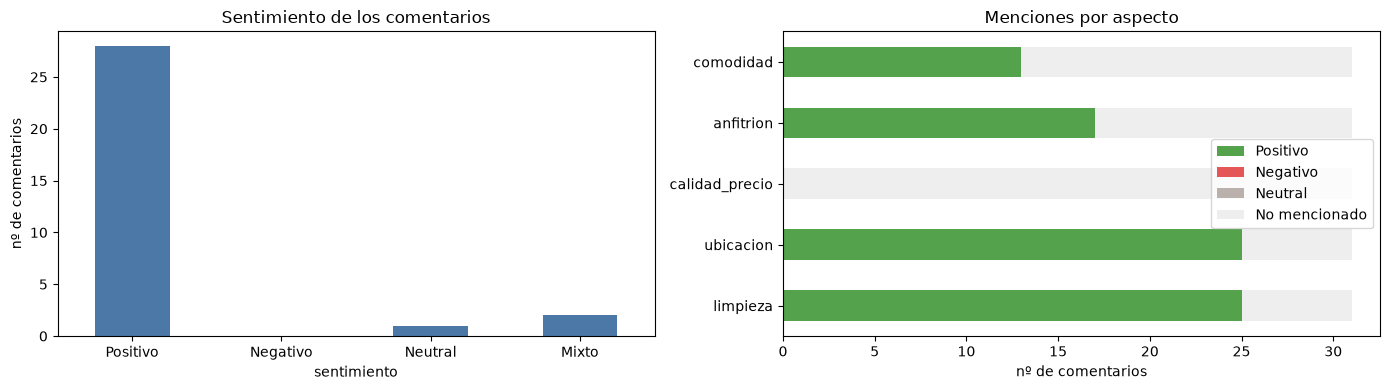

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df_analisis["sentimiento"].value_counts().reindex(VALORES_SENTIMIENTO, fill_value=0).plot(
    kind="bar", ax=axes[0], color="#4C78A8", title="Sentimiento de los comentarios")
axes[0].set_ylabel("nº de comentarios")

(df_analisis[ASPECTOS].apply(lambda s: s.value_counts()).T
 .reindex(columns=VALORES_ASPECTO, fill_value=0)
 .plot(kind="barh", stacked=True, ax=axes[1],
       color=["#54A24B", "#E45756", "#BAB0AC", "#EEEEEE"],
       title="Menciones por aspecto"))
axes[1].set_xlabel("nº de comentarios")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [18]:
def a_texto(df):
    return df.apply(lambda col: col.map(lista_a_texto))


a_texto(df_analisis).to_csv(OUT_DIR / "analisis_comentarios.csv", index=False, encoding="utf-8-sig")
resumen.to_csv(OUT_DIR / "analisis_por_alojamiento.csv", index=False, encoding="utf-8-sig")
print("Guardado en:", OUT_DIR.resolve())

Guardado en: C:\dev\pontia\Prompt engineer\Ejercicio-Prompt-Engineer\ejercicio-1\output


## 9. Conclusiones y justificación de decisiones

**Dos tareas, dos modelos.** La extracción de entidades es abierta (listas,
tamaños, lugares) y usa `openai/gpt-oss-120b`; el análisis de comentarios es
casi todo clasificación en categorías cerradas sobre textos cortos y usa
`openai/gpt-oss-20b`. Cada modelo tiene su propia cuota en Groq, así que las
dos partes no compiten por el mismo límite de tokens por minuto.

**Prompts.**

- Cada campo está **definido** en el prompt, con formato de ejemplo y, cuando se
  agrega después, con **vocabulario cerrado** (`type`, `sentimiento`, aspectos).
- **"Si no aparece, null / No mencionado"**: evita que el modelo rellene datos y
  permite distinguir "no se menciona" de "opinión neutra".
- **Salida en español** independientemente del idioma de entrada, para poder
  comparar y agregar.
- **`ref` corto** en lugar de los `id` de 19 dígitos de AirBnB, que el modelo
  podría copiar mal.

**Gestión de límites.**

- **Lotes**: 5 descripciones o 10 comentarios por llamada → ~4 + ~5 llamadas en
  total, en vez de ~70 si fuera una fila por llamada.
- **`max_tokens=3000`** dimensionado para que el JSON de un lote completo no se
  trunque; si el modelo se salta una fila, `procesar_por_lotes` la reintenta sola.
- **`reasoning_effort="low"`** para que el razonamiento interno de gpt-oss no se
  coma el presupuesto de tokens.
- **Pausas** (`time.sleep`) entre lotes, mayores con el 120B, y manejo del **429**
  con rotación de claves y `Retry-After`, igual que en el Ejercicio 2.
- **Filtro previo sin LLM** de los comentarios cortos: lo que se puede decidir con
  una regla simple no debe gastar llamadas.

**Validación.** El JSON Schema estricto impide valores fuera de rango;
`validar_categorias` lo confirma sobre el resultado (y detectaría filas que
falten), y los cruces con `accommodates`, `property_type` y
`review_scores_*` comprueban que lo extraído es coherente con los datos
estructurados del propio dataset.